# 03 – Exploratory Data Analysis

**Goal:** Visualize the main SQL findings and explore the variables for the default model.

**Data:** `vw_loans` (PostgreSQL view), joined with `dim_date` and `dim_state`.
Charts are saved to `images/` for the README.

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv("../.env")
engine = create_engine(os.getenv("DATABASE_URL"))

IMAGES_DIR = Path("../images")
IMAGES_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


def save_fig(fig, name):
    """Save a chart to the images folder for the README."""
    fig.savefig(IMAGES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

## 2. Load data
All completed loans are loaded with the `is_mature` flag, so the same table can be used for both views.
Year comes from `dim_date` and region from `dim_state`, the same model as in SQL.

In [4]:
LOANS_QUERY = """
SELECT
    l.*,
    d.year,
    d.year_quarter,
    s.region
FROM vw_loans AS l
JOIN dim_date  AS d ON l.issue_date = d.month_date
JOIN dim_state AS s ON l.addr_state = s.state_code
"""
loans = pd.read_sql(LOANS_QUERY, engine, parse_dates=["issue_date"])

print(loans.shape)
print(f"Mature loans: {loans['is_mature'].sum():,}")
loans.dtypes

(1347698, 24)
Mature loans: 676,296


id                         int64
issue_date         datetime64[s]
addr_state                   str
term_months                int64
grade                        str
sub_grade                    str
grade_group                  str
purpose                      str
home_ownership               str
loan_amnt                float64
int_rate                 float64
fico_avg                 float64
fico_band                    str
fico_band_order            int64
dti                      float64
dti_band                     str
dti_band_order             int64
is_default                 int64
net_loss                 float64
net_return               float64
is_mature                  int64
year                       int64
year_quarter                 str
region                       str
dtype: object

## 3. Selection bias
Loans issued after 2015 look riskier when all completed loans are used, because most of them were still open
when the data ends. Mature loans remove this effect (see Q2 and Q2b).

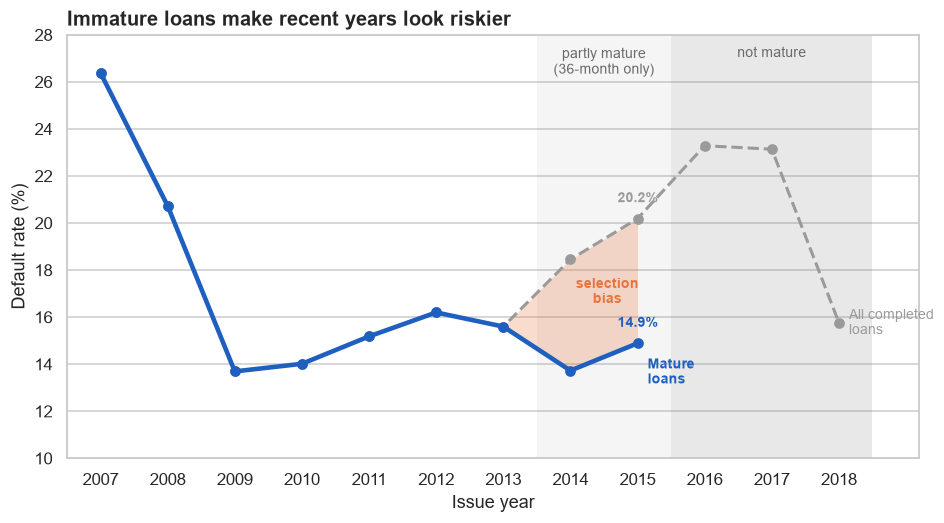

In [8]:
yearly = (
    loans.groupby("year")
    .agg(all_loans=("is_default", "mean"))
    .join(
        loans[loans["is_mature"] == 1]
        .groupby("year")
        .agg(mature_loans=("is_default", "mean"))
    )
    * 100
)

ALL_COLOR = "#9a9a9a"
MATURE_COLOR = "#1f5fbf"
GAP_COLOR = "#e8743b"

fig, ax = plt.subplots(figsize=(10, 5))

# Background: maturity periods
ax.axvspan(2013.5, 2015.5, color="grey", alpha=0.08, lw=0)
ax.axvspan(2015.5, 2018.5, color="grey", alpha=0.18, lw=0)
ax.text(2014.5, 27.5, "partly mature\n(36-month only)", ha="center", va="top", fontsize=9, color="dimgrey")
ax.text(2017, 27.5, "not mature", ha="center", va="top", fontsize=9, color="dimgrey")

# Gap between the two lines = selection bias
gap = yearly.loc[2013:2015]
ax.fill_between(gap.index, gap["mature_loans"], gap["all_loans"], color=GAP_COLOR, alpha=0.25, lw=0)
ax.text(2014.55, 16.6, "selection\nbias", ha="center", fontsize=9, color=GAP_COLOR, fontweight="bold")

# Lines
ax.plot(yearly.index, yearly["all_loans"], color=ALL_COLOR, linestyle="--", marker="o", lw=2)
ax.plot(yearly.index, yearly["mature_loans"], color=MATURE_COLOR, marker="o", lw=3)

# Direct labels instead of a legend
ax.text(2018.15, yearly.loc[2018, "all_loans"], "All completed\nloans", va="center", fontsize=9, color=ALL_COLOR)
ax.text(2015.15, yearly.loc[2015, "mature_loans"] - 0.6, "Mature\nloans", va="top", fontsize=9,
        color=MATURE_COLOR, fontweight="bold")

# Values for 2015
for column, color, offset in [("all_loans", ALL_COLOR, 0.7), ("mature_loans", MATURE_COLOR, 0.7)]:
    value = yearly.loc[2015, column]
    ax.text(2015, value + offset, f"{value:.1f}%", ha="center", fontsize=9, color=color, fontweight="bold")

ax.set_title("Immature loans make recent years look riskier", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("Issue year")
ax.set_ylabel("Default rate (%)")
ax.set_xticks(yearly.index)
ax.set_xlim(2006.5, 2019.2)
ax.set_ylim(10, 28)
ax.grid(axis="x", visible=False)

save_fig(fig, "01_selection_bias")
plt.show()

## 4. Risk segments
Default rate by grade, FICO band and DTI band (mature loans).
Grade combines FICO, DTI and other information, so it separates risk much better than any single variable.

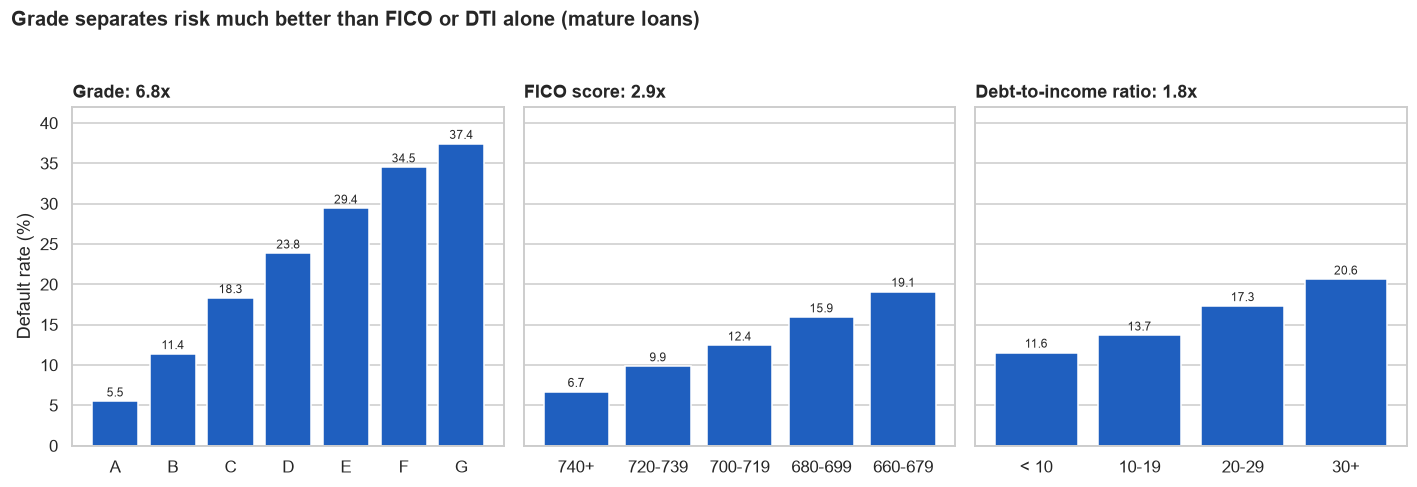

In [12]:
mature = loans[loans["is_mature"] == 1]


def default_rate_by(column, order_column=None, exclude=(), reverse=False):
    """Default rate (%) by group, sorted by an order column."""
    data = mature[~mature[column].isin(exclude)]
    order_column = order_column or column
    result = (
        data.groupby(column, observed=True)
        .agg(default_rate=("is_default", "mean"), order=(order_column, "min"))
        .sort_values("order", ascending=not reverse)
    )
    result["default_rate"] *= 100
    return result


panels = [
    ("Grade", default_rate_by("grade")),
    ("FICO score", default_rate_by("fico_band", "fico_band_order", exclude=["< 660"], reverse=True)),
    ("Debt-to-income ratio", default_rate_by("dti_band", "dti_band_order", exclude=["Missing"])),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)

for ax, (title, data) in zip(axes, panels):
    labels = data.index.astype(str)
    ax.bar(labels, data["default_rate"], color=MATURE_COLOR)

    for i, value in enumerate(data["default_rate"]):
        ax.text(i, value + 0.6, f"{value:.1f}", ha="center", fontsize=8)

    ratio = data["default_rate"].max() / data["default_rate"].min()
    ax.set_title(f"{title}: {ratio:.1f}x", loc="left", fontweight="bold")
    ax.grid(axis="x", visible=False)

axes[0].set_ylabel("Default rate (%)")
axes[0].set_ylim(0, 42)
fig.suptitle(
    "Grade separates risk much better than FICO or DTI alone (mature loans)",
    x=0.01, ha="left", fontsize=13, fontweight="bold",
)
fig.tight_layout(rect=[0, 0, 1, 0.95])

save_fig(fig, "02_risk_segments")
plt.show()

## 5. Risk and return
Loss rate and net return rate by grade group (36-month mature loans, so all groups have the same interest period).
Net return = total payments − loan amount, over the life of the loan.

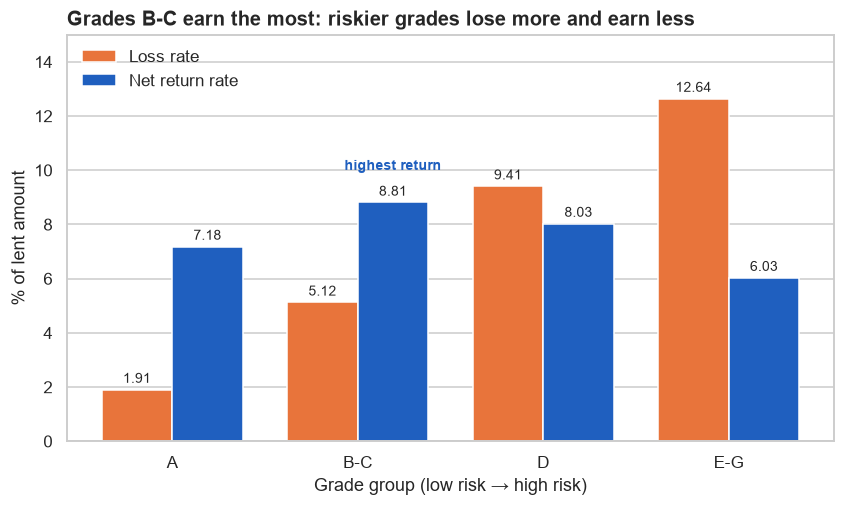

In [15]:
term36 = mature[mature["term_months"] == 36]

by_group = term36.groupby("grade_group", observed=True)[["loan_amnt", "net_loss", "net_return"]].sum()
by_group["loss_rate"] = by_group["net_loss"] / by_group["loan_amnt"] * 100
by_group["return_rate"] = by_group["net_return"] / by_group["loan_amnt"] * 100

x = np.arange(len(by_group))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.8))
loss_bars = ax.bar(x - width / 2, by_group["loss_rate"], width, color=GAP_COLOR, label="Loss rate")
return_bars = ax.bar(x + width / 2, by_group["return_rate"], width, color=MATURE_COLOR, label="Net return rate")

for bars in (loss_bars, return_bars):
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.25,
            f"{bar.get_height():.2f}", ha="center", fontsize=9,
        )

best = by_group["return_rate"].idxmax()
best_position = list(by_group.index).index(best)
ax.annotate(
    "highest return", xy=(best_position + width / 2, by_group.loc[best, "return_rate"] + 1.2),
    ha="center", fontsize=9, color=MATURE_COLOR, fontweight="bold",
)

ax.set_xticks(x, by_group.index)
ax.set_xlabel("Grade group (low risk → high risk)")
ax.set_ylabel("% of lent amount")
ax.set_ylim(0, 15)
ax.set_title("Grades B-C earn the most: riskier grades lose more and earn less",
             loc="left", fontsize=13, fontweight="bold")
ax.legend(loc="upper left", frameon=False)
ax.grid(axis="x", visible=False)

save_fig(fig, "03_risk_return")
plt.show()

## 6. Approval rate
Accepted and rejected applications by year (`vw_approval_monthly`).
Applications grew much faster than approvals after 2015, so the approval rate fell from 15% (2013) to 5% (2018).

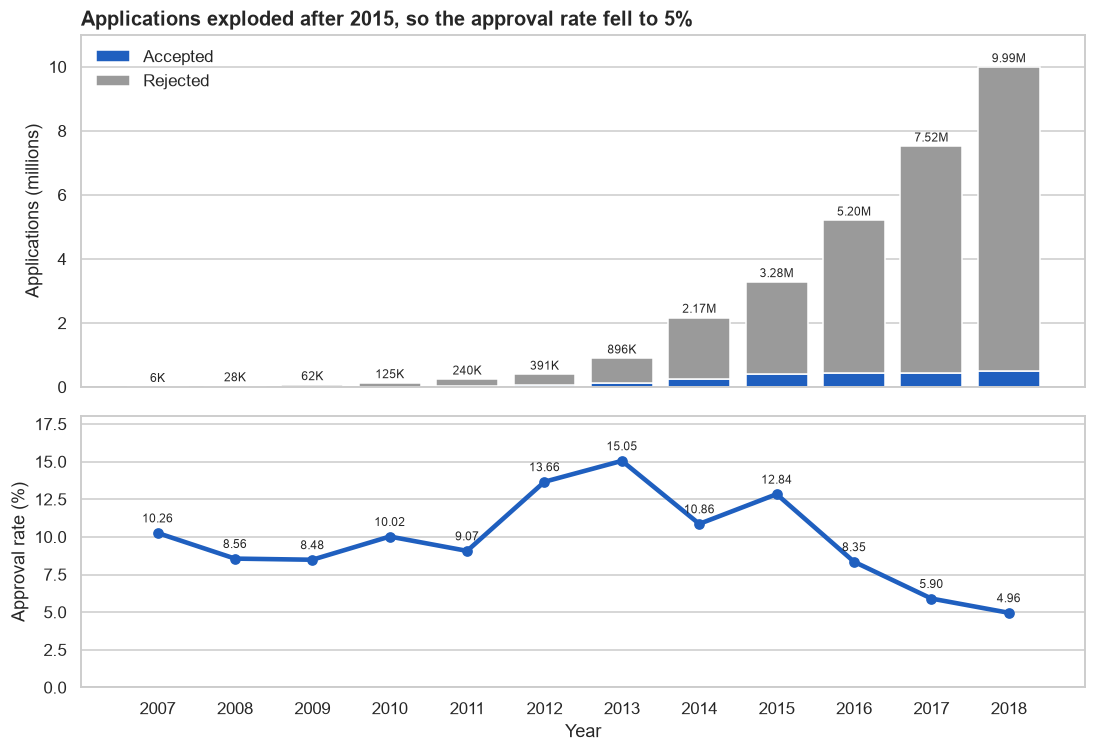

In [17]:
def format_count(value):
    """Short label for large counts: 9.99M, 125K or the exact number."""
    if value >= 1_000_000:
        return f"{value / 1e6:.2f}M"
    if value >= 1_000:
        return f"{value / 1e3:.0f}K"
    return f"{value:,.0f}"

APPROVAL_QUERY = """
SELECT
    d.year,
    SUM(a.accepted_count) AS accepted_count,
    SUM(a.rejected_count) AS rejected_count
FROM vw_approval_monthly AS a
JOIN dim_date AS d ON a.month = d.month_date
GROUP BY d.year
ORDER BY d.year
"""

approval = pd.read_sql(APPROVAL_QUERY, engine).set_index("year")
approval["approval_rate"] = (
    approval["accepted_count"] / (approval["accepted_count"] + approval["rejected_count"]) * 100
)

fig, (ax_top, ax_bottom) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]}
)

# Top: applications (millions)
ax_top.bar(approval.index, approval["accepted_count"] / 1e6, color=MATURE_COLOR, label="Accepted")
ax_top.bar(
    approval.index, approval["rejected_count"] / 1e6,
    bottom=approval["accepted_count"] / 1e6, color=ALL_COLOR, label="Rejected",
)
total_applications = approval["accepted_count"] + approval["rejected_count"]
for year, total in total_applications.items():
    ax_top.text(year, total / 1e6 + 0.15, format_count(total), ha="center", fontsize=8)

ax_top.set_ylim(0, 11)
ax_top.set_ylabel("Applications (millions)")
ax_top.legend(loc="upper left", frameon=False)
ax_top.grid(axis="x", visible=False)
ax_top.set_title("Applications exploded after 2015, so the approval rate fell to 5%",
                 loc="left", fontsize=13, fontweight="bold")

# Bottom: approval rate
ax_bottom.plot(approval.index, approval["approval_rate"], color=MATURE_COLOR, marker="o", lw=3)
for year, value in approval["approval_rate"].items():
    ax_bottom.text(year, value + 0.7, f"{value:.2f}", ha="center", fontsize=8)

ax_bottom.set_ylabel("Approval rate (%)")
ax_bottom.set_xlabel("Year")
ax_bottom.set_ylim(0, 18)
ax_bottom.set_xticks(approval.index)
ax_bottom.grid(axis="x", visible=False)

fig.tight_layout()
save_fig(fig, "04_approval_rate")
plt.show()

**2007–2011 had fewer than 250,000 applications per year.**

## 7. Variables for the model
Only information known **at origination** is used. Outcome columns (`loan_status`, `total_pymnt`,
`recoveries`, `net_loss`) are excluded to avoid data leakage.
Each numeric variable is split into 5 equal-sized groups (quintiles) and the default rate is compared across groups.

In [18]:
MODEL_QUERY = """
SELECT
    id, issue_date, term_months, grade, sub_grade,
    loan_amnt, int_rate, installment,
    emp_length_years, home_ownership, annual_inc, verification_status, purpose,
    dti, fico_avg, revol_util, open_acc, delinq_2yrs, inq_last_6mths,
    is_default
FROM loans_mature
"""

model_data = pd.read_sql(MODEL_QUERY, engine, parse_dates=["issue_date"])
print(model_data.shape)

(676296, 20)


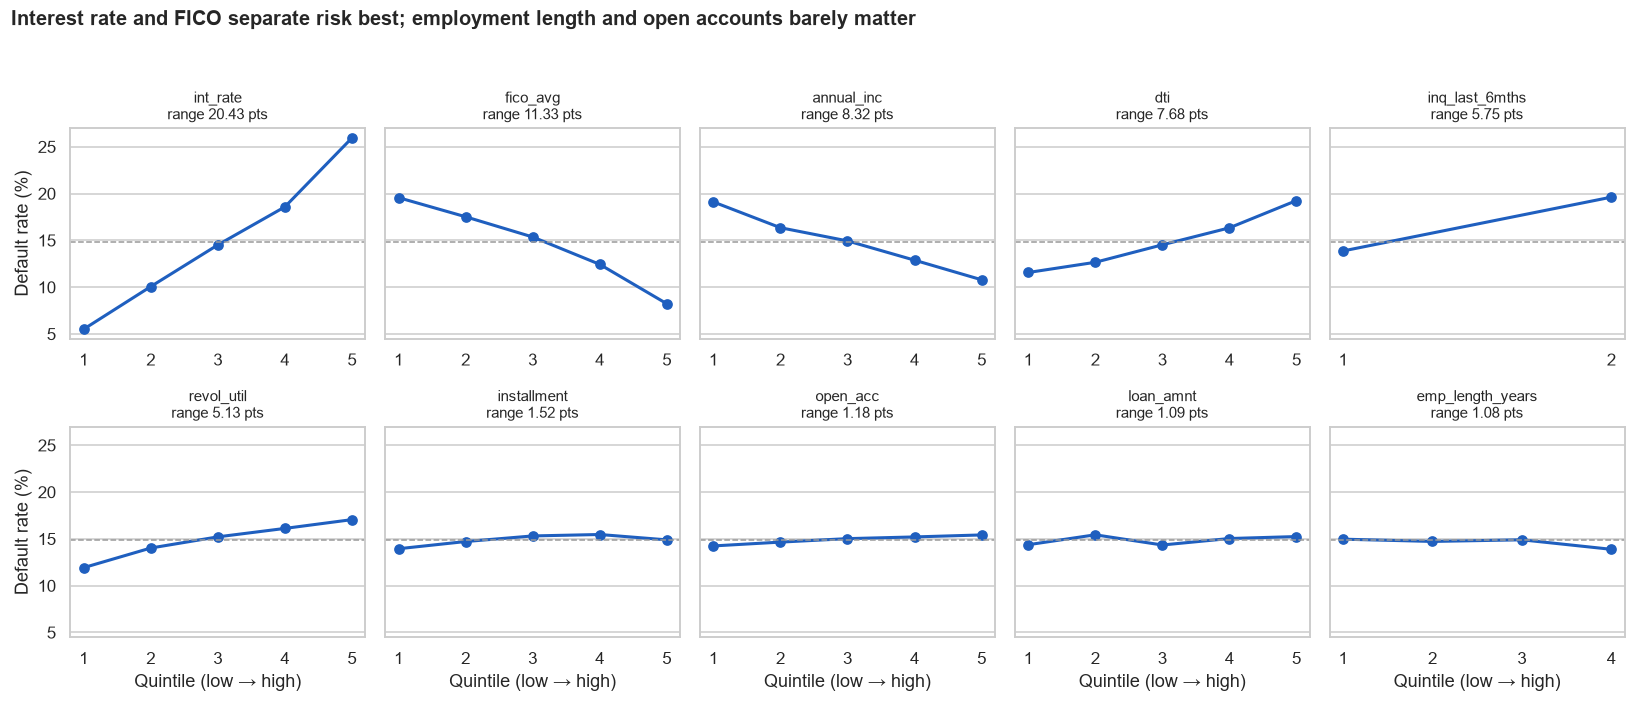

In [19]:
NUMERIC_FEATURES = [
    "int_rate", "fico_avg", "annual_inc", "dti", "revol_util",
    "inq_last_6mths", "loan_amnt", "installment", "open_acc", "emp_length_years",
]

overall_rate = model_data["is_default"].mean() * 100

# 1) Default rate by quintile for each variable
rates = {}
for feature in NUMERIC_FEATURES:
    groups = pd.qcut(model_data[feature], 5, duplicates="drop")
    rates[feature] = model_data.groupby(groups, observed=True)["is_default"].mean() * 100

# 2) Sort variables by how much they separate risk (max - min, in points)
spread = {feature: rate.max() - rate.min() for feature, rate in rates.items()}
ordered = sorted(spread, key=spread.get, reverse=True)

# 3) Plot
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5), sharey=True)

for ax, feature in zip(axes.flat, ordered):
    rate = rates[feature]
    positions = range(1, len(rate) + 1)
    ax.plot(positions, rate.values, marker="o", color=MATURE_COLOR, lw=2)
    ax.axhline(overall_rate, color=ALL_COLOR, linestyle="--", lw=1)
    ax.set_title(f"{feature}\nrange {spread[feature]:.2f} pts", fontsize=10)
    ax.set_xticks(list(positions))
    ax.grid(axis="x", visible=False)

for ax in axes[:, 0]:
    ax.set_ylabel("Default rate (%)")
for ax in axes[1]:
    ax.set_xlabel("Quintile (low → high)")

fig.suptitle(
    "Interest rate and FICO separate risk best; employment length and open accounts barely matter",
    x=0.01, ha="left", fontsize=13, fontweight="bold",
)
fig.tight_layout(rect=[0, 0, 1, 0.95])

save_fig(fig, "05_feature_quintiles")
plt.show()

In [20]:
# 1) inq_last_6mths with manual groups: 0, 1, 2, 3+
inq_groups = pd.cut(
    model_data["inq_last_6mths"], bins=[-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"]
)
inq_check = (
    model_data.groupby(inq_groups, observed=True)["is_default"]
    .agg(loan_count="size", default_rate="mean")
)
inq_check["default_rate"] = (inq_check["default_rate"] * 100).round(2)
print(inq_check, "\n")

# 2) Missing employment length vs known
emp_check = (
    model_data.groupby(model_data["emp_length_years"].isna())["is_default"]
    .agg(loan_count="size", default_rate="mean")
    .rename(index={False: "known", True: "missing (Unknown)"})
)
emp_check["default_rate"] = (emp_check["default_rate"] * 100).round(2)
print(emp_check)

                loan_count  default_rate
inq_last_6mths                          
0                   373846         12.80
1                   185112         16.04
2                    74069         18.61
3+                   43244         21.33 

                   loan_count  default_rate
emp_length_years                           
known                  638693         14.51
missing (Unknown)       37603         20.86
